# From saved hippocampal cue inputs to verified endpoint predictions
## Executed, inspectable model walkthrough for scientific review

**Question:** In the October 7 exploratory endpoint assay, what information about
start, goal and ordered start–goal pair was recoverable from constructed cue populations?
Does adding navigation during CEBRA-Time training improve all three readouts?

**Review artifact:** this notebook, including executed code, mathematical walkthroughs,
figures, provenance and final verification summary. It uses the accepted saved run—not
new model fitting. Read top to bottom; each figure states its evaluation object.

**Claim ceiling:** 195 selected neurons across 58 recording sessions are combined into
label-conditioned **pseudopopulations**, not a simultaneous 195-neuron recording.
Development sources have been inspected before. Computational seeds are not biological
replicates. Endpoint classification is not prospective path prediction, intention,
neural dynamics or formal state observability. Here *observable* means inspectable computation.

### What actually executes?
| Stage | Status in this notebook |
|---|---|
| Spike import, source splitting, assembly and fitting | Historical; explained, not rerun |
| Saved input/scaler/lineage identity | Hash checked; shapes, labels and source disjointness checked |
| PCA and six fitted CEBRA encoders | Forward transformations replayed on saved standardized cue arrays |
| 495 fitted readouts, including raw SVD-LDA | Replayed for all three seeds, ten bins and whole cue |
| Predictions and 990 train/development score rows | Compared with saved artifacts and tracked metrics |
| Figures and worked arithmetic | Regenerated from authenticated saved evidence/replayed results |
| Navigation, null worlds, raw recordings, new fits | Not opened or executed |

The saved standardized cue arrays are the **starting point** for numerical replay.
The original scaler fit and source-to-array reconstruction are **not newly verified** here.
The original full replay receipt is historical evidence, not a substitute for this narrower
notebook's checks. The [methods/results](../docs/reports/cebra-endpoint-time-readout-20261006/README.md)
and [protocol](../docs/reports/cebra-endpoint-time-readout-20261006/protocol.md) remain the scientific sources.
Their old PR-status text is historical; use the current repository for publication status.

**Reading versus rerunning:** committed outputs are aggregate-only and readable without
private data. Rerunning requires the authenticated local saved run, compatible runtime and
CUDA. Missing inputs cause a failure, not a download, synthetic fallback or retraining.


In [1]:
from pathlib import Path
from collections import Counter
from io import BytesIO
import csv, hashlib, html, os, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.mathtext import math_to_image
from IPython.display import display, HTML, Image

%matplotlib inline
plt.rcParams.update({'figure.dpi': 115, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/neuro').is_dir())
for directory in (ROOT / 'src', ROOT / 'report'):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
from endpoint_replay import (SavedRun, RUN_RELATIVE, MANIFEST_SHA256, REPRESENTATIONS,
                             TARGETS, WINDOWS, runtime_report, load_seed,
                             replay_features, replay_readouts, no_fitting)
from neuro.studies import endpoint_time_readout as ep
RUN = SavedRun(os.environ.get('NEURO_SAVED_RUN', ROOT / RUN_RELATIVE))
versions = runtime_report(RUN)

def table(headers, rows):
    content = '<table><thead><tr>' + ''.join('<th>' + html.escape(str(v)) + '</th>' for v in headers) + '</tr></thead><tbody>'
    content += ''.join('<tr>' + ''.join('<td>' + html.escape(str(v)) + '</td>' for v in row) + '</tr>' for row in rows)
    display(HTML(content + '</tbody></table>'))

def equation(latex):
    # Render into the notebook output: readable offline, without MathJax or TeX.
    output = BytesIO()
    math_to_image('$' + latex + '$', output, dpi=160, format='png', color='#173d52')
    display(Image(data=output.getvalue(), format='png'))

def show(fig):
    display(fig)
    plt.close(fig)

table(['Scientific dependency', 'Verified version'], sorted(versions.items()))
print('Saved manifest SHA256:', MANIFEST_SHA256)
print('Backend: original CUDA; no CPU fallback. Package version gate passed.')


Scientific dependency,Verified version
cebra,0.6.1
joblib,1.5.2
numpy,2.3.4
scikit-learn,1.7.2
torch,2.12.0


Saved manifest SHA256: e0f88a72b436b6fd86299c5e4575af2137904b4e21c57a7fbaa392661b802a36
Backend: original CUDA; no CPU fallback. Package version gate passed.


## 1. The measurement and inference chain

Recorded spikes are measured; bins, assembled populations, features and predictions are
derived. One real source trial contributes **all selected neurons from its session and all
ten cue bins** to an assembled row. It does not contribute an isolated neuron sampled independently.

The gray boxes below are **historical operations**, not fresh computation. The blue boxes
are replayed from saved artifacts. Arrows specify dependencies, not causal claims about the brain.


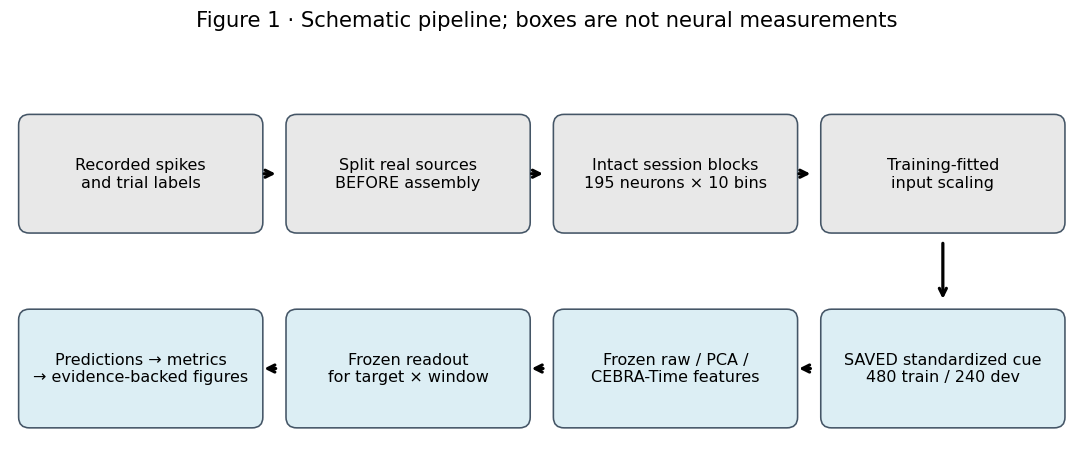

In [2]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.set(xlim=(0, 12), ylim=(0, 4.8)); ax.axis('off')
boxes = [(0.2, 2.7, 'Recorded spikes\nand trial labels', '#e8e8e8'),
         (3.2, 2.7, 'Split real sources\nBEFORE assembly', '#e8e8e8'),
         (6.2, 2.7, 'Intact session blocks\n195 neurons × 10 bins', '#e8e8e8'),
         (9.2, 2.7, 'Training-fitted\ninput scaling', '#e8e8e8'),
         (9.2, 0.5, 'SAVED standardized cue\n480 train / 240 dev', '#dceef4'),
         (6.2, 0.5, 'Frozen raw / PCA /\nCEBRA-Time features', '#dceef4'),
         (3.2, 0.5, 'Frozen readout\nfor target × window', '#dceef4'),
         (0.2, 0.5, 'Predictions → metrics\n→ evidence-backed figures', '#dceef4')]
for x, y, label, color in boxes:
    ax.add_patch(FancyBboxPatch((x, y), 2.5, 1.1, boxstyle='round,pad=0.12', fc=color, ec='#456'))
    ax.text(x+1.25, y+0.55, label, ha='center', va='center', fontsize=10)
for start, end in [((2.8,3.25),(3.0,3.25)), ((5.8,3.25),(6.0,3.25)),
                   ((8.8,3.25),(9.0,3.25)), ((10.45,2.5),(10.45,1.8)),
                   ((9.0,1.05),(8.8,1.05)), ((6.0,1.05),(5.8,1.05)), ((3.0,1.05),(2.8,1.05))]:
    ax.annotate('', xy=end, xytext=start, arrowprops={'arrowstyle':'->', 'lw':2})
ax.set_title('Figure 1 · Schematic pipeline; boxes are not neural measurements')
show(fig)


### Spike counts and source assembly: the math, not a new import

For trial *r*, neuron *u*, bin *b* and spike times *t*, the count is the number of spikes
inside the half-open 100-ms interval. These are **counts, not Hz**. The displayed equation
is the mathematical intent; exact historical boundary replay also depends on imported
timestamp serialization and floating-point bin assignment. Neither is recomputed here.

For each condition *k* and session *s*, the assembler drew a source from that split's
eligible pool. All units in the session and all bins travel together. Reuse across rows
is allowed, so more rows do not imply more recorded trials. Known labels condition even
development assembly; this is not an unknown-label deployment pipeline.


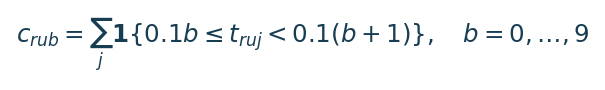

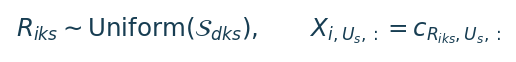

Quantity,Training,Development,Meaning
Eligible real sources,"12,288","3,265",Historical cohort; not new recordings
Pair-conditioned rows,30 × 16 = 480,30 × 8 = 240,Per computational seed
Rows per start / goal,5 × 16 = 80,5 × 8 = 40,"Same rows, separate label heads"
Session-block selections,"480 × 58 = 27,840","240 × 58 = 13,920","Selections, not distinct sources"


In [3]:
equation(r'c_{rub}=\\sum_j \\mathbf{1}\\{0.1b \\leq t_{ruj}<0.1(b+1)\\},\\quad b=0,\\ldots,9'.replace('\\\\','\\'))
equation(r'R_{iks}\\sim\\mathrm{Uniform}(\\mathcal{S}_{dks}),\\qquad X_{i,U_s,:}=c_{R_{iks},U_s,:}'.replace('\\\\','\\'))
table(['Quantity', 'Training', 'Development', 'Meaning'], [
    ['Eligible real sources', '12,288', '3,265', 'Historical cohort; not new recordings'],
    ['Pair-conditioned rows', '30 × 16 = 480', '30 × 8 = 240', 'Per computational seed'],
    ['Rows per start / goal', '5 × 16 = 80', '5 × 8 = 40', 'Same rows, separate label heads'],
    ['Session-block selections', '480 × 58 = 27,840', '240 × 58 = 13,920', 'Selections, not distinct sources'],
])


## 2. Inspect the actual saved inputs and lineage

We load the **observed** seeds 0–2, authenticate each opened file against the pinned run
manifest, and verify shape, class support, one block per row/session and source disjointness.
Private source identifiers stay in memory; only counts are displayed. This verifies the
saved lineage record, not that every neural value was reconstructed from raw recordings.

Recorded development lineage uses the historical word `validation`; the notebook consistently
calls that **exposed development**, not a pristine validation/test set.


In [4]:
cues, labels, input_scalers, lineage = {}, {}, {}, {}
for seed in range(3):
    cues[seed], labels[seed], input_scalers[seed], lineage[seed] = load_seed(RUN, seed)
table(['Seed', 'Split', 'Saved cue shape', 'Source selections', 'Distinct used sources', 'Mean uses'], [
    [seed, split, str(cues[seed][split].shape), lineage[seed][split]['selections'],
     lineage[seed][split]['distinct_used_sources'],
     f"{lineage[seed][split]['selections'] / lineage[seed][split]['distinct_used_sources']:.3f}"]
    for seed in range(3) for split in ('train', 'development')
])
print('PASS: shapes/dtypes, pair balance, complete session blocks and train/development source disjointness.')


Seed,Split,Saved cue shape,Source selections,Distinct used sources,Mean uses
0,train,"(480, 195, 10)",27840,10906,2.553
0,development,"(240, 195, 10)",13920,3212,4.334
1,train,"(480, 195, 10)",27840,10885,2.558
1,development,"(240, 195, 10)",13920,3208,4.339
2,train,"(480, 195, 10)",27840,10875,2.560
2,development,"(240, 195, 10)",13920,3223,4.319


PASS: shapes/dtypes, pair balance, complete session blocks and train/development source disjointness.


### Real-source distributions are not the same as balanced constructed rows

Figure 2 sums the saved session-by-pair support table into ordered-pair, start and goal
marginals. This is new **presentation arithmetic on saved counts**, not raw-data extraction.
The sums must recover 12,288/3,265 sources. Each source has one pair, one start and one goal;
the three panels are views of the same source population, not independent samples.

The source pools can be uneven although synthetic rows are exactly balanced. These plots
show support; they do **not** establish why a particular class or method performs better.


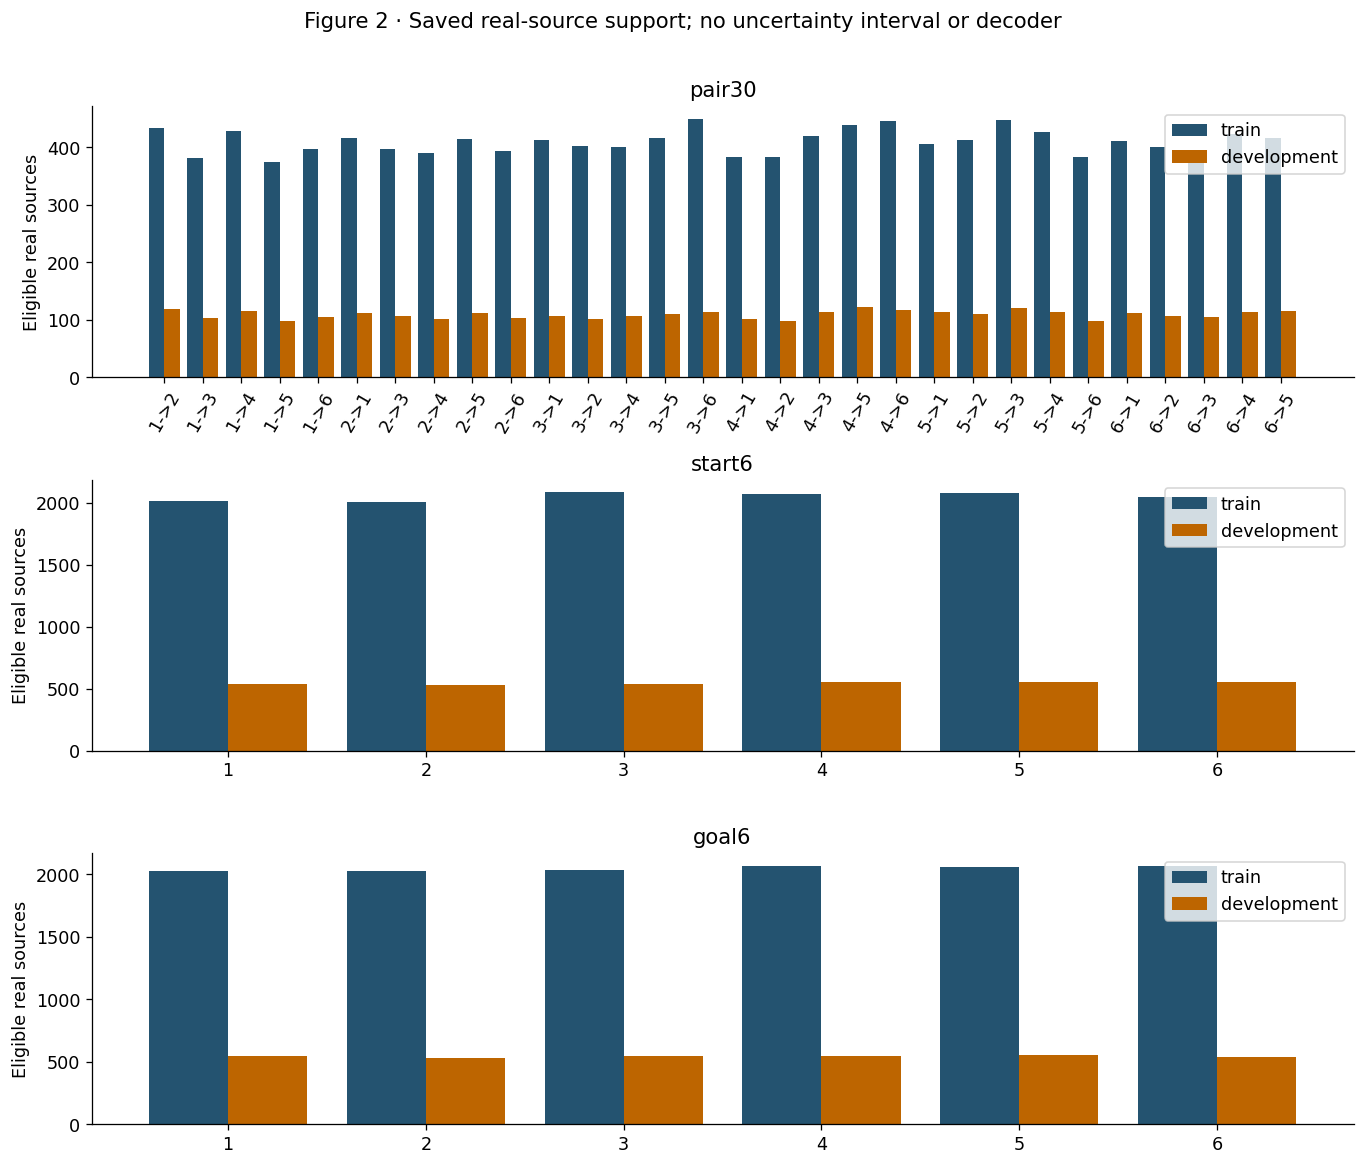

Endpoint ID,Start train,Start dev,Goal train,Goal dev
1,2013,538,2026,545
2,2008,532,2031,533
3,2081,539,2039,547
4,2070,551,2067,550
5,2075,554,2058,554
6,2041,551,2067,536


In [5]:
support = RUN.json('source_support.json')
source_counts = {}
for split in ('train', 'development'):
    pairs = Counter()
    for row in support:
        if row['split'] == split:
            pairs[row['label']] += int(row['sources'])
    assert set(pairs) == set(ep.PAIR_LABELS)
    source_counts[split] = {
        'pair30': np.array([pairs[k] for k in ep.PAIR_LABELS]),
        'start6': np.array([sum(v for k,v in pairs.items() if int(k.split('->')[0]) == s) for s in range(1,7)]),
        'goal6': np.array([sum(v for k,v in pairs.items() if int(k.split('->')[1]) == g) for g in range(1,7)]),
    }
    for counts in source_counts[split].values():
        assert counts.sum() == (12288 if split == 'train' else 3265)
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, target in zip(axes, TARGETS, strict=True):
    names = ep.PAIR_LABELS if target == 'pair30' else list(range(1,7))
    x = np.arange(len(names))
    for offset, split, color in [(-0.2,'train','#245370'), (0.2,'development','#bd6500')]:
        ax.bar(x+offset, source_counts[split][target], width=0.4, label=split, color=color)
    ax.set_xticks(x, names, rotation=60 if target == 'pair30' else 0)
    ax.set(ylabel='Eligible real sources', title=target)
    ax.legend()
fig.suptitle('Figure 2 · Saved real-source support; no uncertainty interval or decoder', y=1.01)
fig.tight_layout(); show(fig)
table(['Endpoint ID', 'Start train', 'Start dev', 'Goal train', 'Goal dev'], [
    [k+1, source_counts['train']['start6'][k], source_counts['development']['start6'][k],
     source_counts['train']['goal6'][k], source_counts['development']['goal6'][k]] for k in range(6)
])


## 3. Scaling and the meaning of a population bin

The saved input scaler was fitted to **480 × 10 = 4,800 assembled training-bin vectors**,
not to 12,288 equally weighted unique source trials. Source reuse therefore affects the
fitted statistics through its frequency in the assemblies. Its 195 means/scales are reused
unchanged for development and, historically, training-navigation inputs.

The equation uses population variance (denominator *N*); `StandardScaler` handles zero/near-zero
scales with its constant-feature convention. **We restore the saved values, not recompute the fit.**
The numerical diagnostic below checks the saved standardized arrays and makes no claim to
reconstruct original spike counts. A nonzero numerical residue is floating-point arithmetic,
not neural variability.


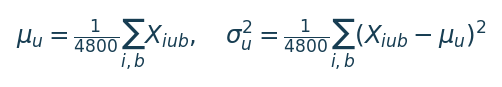

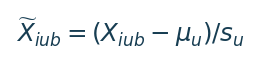

Seed,Nonconstant features,Max |training mean|,Max |training variance − 1|
0,195,3.72e-08,7.94e-08
1,195,4.62e-08,1.16e-07
2,195,4.1e-08,8.49e-08


In [6]:
equation(r'\\mu_u=\\frac{1}{4800}\\sum_{i,b}X_{iub},\\quad \\sigma_u^2=\\frac{1}{4800}\\sum_{i,b}(X_{iub}-\\mu_u)^2'.replace('\\\\','\\'))
equation(r'\\widetilde{X}_{iub}=(X_{iub}-\\mu_u)/s_u'.replace('\\\\','\\'))
scaling_diagnostics = []
for seed in range(3):
    pooled = cues[seed]['train'].transpose(0,2,1).reshape(4800,195)
    active = input_scalers[seed]['var'] > 0
    scaling_diagnostics.append([seed, int(active.sum()),
        f'{np.abs(pooled.mean(axis=0, dtype=np.float64)).max():.3g}',
        f'{np.abs(pooled.var(axis=0, dtype=np.float64)[active]-1).max():.3g}'])
table(['Seed', 'Nonconstant features', 'Max |training mean|', 'Max |training variance − 1|'], scaling_diagnostics)


### Shared mappings, then different readout views

A **single shared PCA basis** and each **single pointwise CEBRA encoder** operate on every
100-ms bin. They are not fitted independently for the ten bins. PCA uses pooled training
bins, eight components and no whitening. CEBRA-Time maps a 195-feature bin to eight
unit-normalized coordinates; it is not a recurrent state estimator.

Selecting one bin gives 195 raw or eight reduced features. Concatenating all ten gives
1,950 raw or 80 reduced features, **not** an eight-dimensional whole-cue state.
Raw flattening is unit-major then time; reduced flattening is time-major then coordinate.
The replay uses the package's window extraction, preserving these different orders.


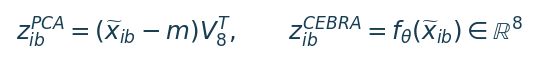

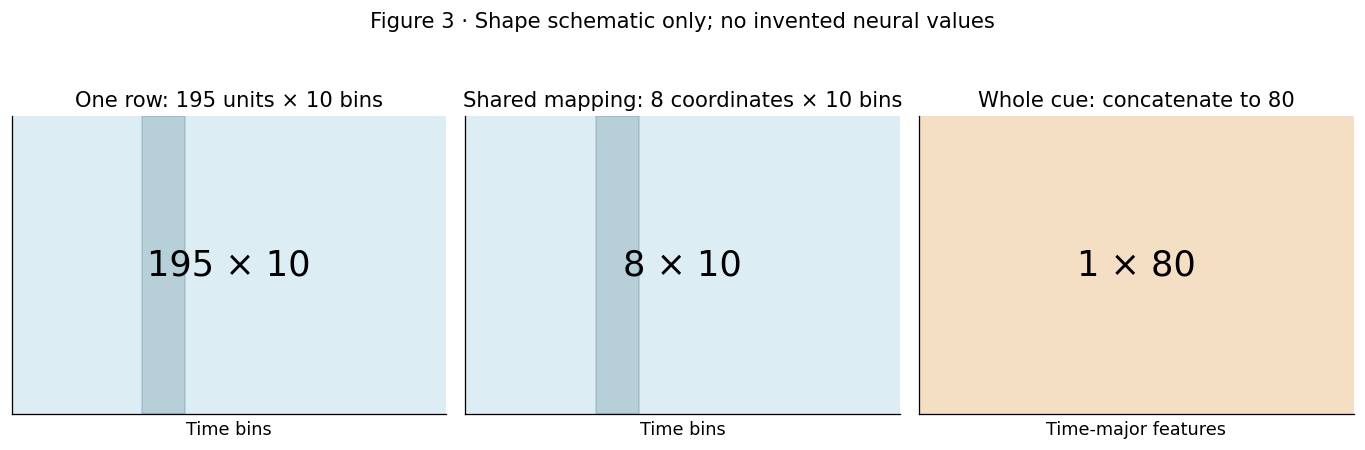

In [7]:
equation(r'z^{PCA}_{ib}=(\\widetilde{x}_{ib}-m)V_8^T,\\qquad z^{CEBRA}_{ib}=f_\\theta(\\widetilde{x}_{ib})\\in\\mathbb{R}^8'.replace('\\\\','\\'))
fig, axes = plt.subplots(1,3,figsize=(12,3.7))
for ax, shape, title, color in zip(axes, [(195,10),(8,10),(1,80)],
    ['One row: 195 units × 10 bins', 'Shared mapping: 8 coordinates × 10 bins', 'Whole cue: concatenate to 80'],
    ['#dceef4','#dceef4','#f4dec4'], strict=True):
    ax.set_facecolor(color)
    ax.set(xlim=(0,shape[1]), ylim=(0,shape[0]), title=title)
    ax.set_xticks([]); ax.set_yticks([])
    ax.text(shape[1]/2,shape[0]/2,f'{shape[0]} × {shape[1]}',ha='center',va='center',fontsize=22)
    if shape[1]==10:
        ax.axvspan(3,4,color='#245370',alpha=0.2)
    ax.set_xlabel('Time bins' if shape[1]==10 else 'Time-major features')
fig.suptitle('Figure 3 · Shape schematic only; no invented neural values', y=1.05)
fig.tight_layout(); show(fig)


## 4. Restore the fitted representations and replay their forward passes

**Training context, not executed training:** cue-only Time contrasts neighboring cue bins
within a constructed row. Joint Time samples cue/navigation phases 50/50 at the same
1,000-update budget; navigation pairing uses adjacent native bins within each source block.
Only training sources contributed navigation. The intervention adds navigation **and changes
cue exposure**, so it does not isolate the causal effect of navigation content.

The similarity below describes the Time objective's attraction/repulsion signal; it is not
a claim to reproduce the library's full InfoNCE denominator/reduction. Neither encoder
optimization nor readout fitting is run here. Time-based contrastive pairing also does not
make the complete pipeline label-free: assembly uses known endpoint labels.

Numerical replay restores the saved float32 PCA state and calls sklearn's `PCA.transform`
(the order of floating-point operations matters). CEBRA uses authenticated checkpoints,
restricted `weights_only=True` loading and the original CUDA backend. The current package
is reused as current code; **historical approvals/hashes are not rewritten or spoofed**.


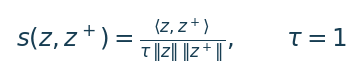

Seed,Split,Representation,Shape,Max absolute replay error
0,train,raw,"(480, 1950)",0
0,train,pca8,"(480, 80)",0
0,train,cebra_cue,"(480, 80)",0
0,train,cebra_joint,"(480, 80)",0
0,development,raw,"(240, 1950)",0
0,development,pca8,"(240, 80)",0
0,development,cebra_cue,"(240, 80)",0
0,development,cebra_joint,"(240, 80)",0
1,train,raw,"(480, 1950)",0
1,train,pca8,"(480, 80)",0


Actual restored cue-only network architecture (seed 0):
Offset0Model(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=195, out_features=32, bias=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=32, out_features=32, bias=True)
    (4): GELU(approximate='none')
    (5): Linear(in_features=32, out_features=16, bias=True)
    (6): GELU(approximate='none')
    (7): Linear(in_features=16, out_features=8, bias=True)
    (8): _Norm()
    (9): Squeeze()
  )
)
PASS: all six encoders and three PCA states replayed on both splits; no fits.


In [8]:
equation(r's(z,z^+)=\\frac{\\langle z,z^+\\rangle}{\\tau\\,\\|z\\|\\,\\|z^+\\|},\\qquad\\tau=1'.replace('\\\\','\\'))
features, feature_errors, architectures = {}, [], {}
for seed in range(3):
    features[seed], errors, architectures[seed] = replay_features(RUN, seed, cues[seed])
    feature_errors.extend(errors)
table(['Seed','Split','Representation','Shape','Max absolute replay error'], [
    [r['seed'],r['split'],r['representation'],str(features[r['seed']][r['split']][r['representation']].shape),
     f"{r['max_abs_error']:.3g}"] for r in feature_errors
])
print('Actual restored cue-only network architecture (seed 0):')
print(architectures[0]['cebra_cue'])
print('PASS: all six encoders and three PCA states replayed on both splits; no fits.')


The table compares **recomputed features** with the saved arrays. It is not merely reading
stored scores. The feature tolerance is explicitly `rtol=1e-7, atol=1e-6`; actual errors are
shown rather than hidden by a pass label. Exact matches on this machine do not guarantee
bitwise portability to other GPUs or library versions.

An eight-dimensional code and a reproducible forward pass do not establish a biological
manifold, shared cue/navigation geometry or a complete hippocampal state.

## 5. The saved decoder: make the prediction math inspectable

Every target × representation × window has its own **second training-fitted scaler** and
classifier. The logistic models use `C=0.01`, `lbfgs`, at most 2,000 iterations. The three
target heads are independently fitted; start/goal are **not** marginals of pair predictions.
`C` controls regularization, but we do not equate it with an exact penalty coefficient
without sklearn's normalization convention. Raw SVD-LDA is supervised and not dimension-matched.

For the logistic readout, standardize the feature vector, multiply by saved weights, add
intercepts, then apply softmax. The next cell checks that equation against the saved
cue-only/pair30/whole-cue probabilities at seed0. It computes on all 240 development rows
but publishes only a numerical error summary—not private row-level predictions.


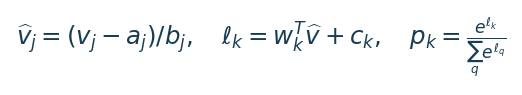

Worked softmax check: 240 rows × 30 classes; max absolute probability error = 6.96e-09


In [9]:
equation(r'\\widehat{v}_j=(v_j-a_j)/b_j,\\quad \\ell_k=w_k^T\\widehat{v}+c_k,\\quad p_k=\\frac{e^{\\ell_k}}{\\sum_q e^{\\ell_q}}'.replace('\\\\','\\'))
state_base = 'observed/seed0/readouts/cebra_cue/wholecue/pair30'
state = RUN.arrays(state_base + '/readout_state.npz')
v = features[0]['development']['cebra_cue']
scaled_v = (v - state['scaler_mean']) / state['scaler_scale']
logits = scaled_v @ state['coef'].T + state['intercept']
logits -= logits.max(axis=1, keepdims=True)  # numerically stable, same probabilities
prob_math = np.exp(logits); prob_math /= prob_math.sum(axis=1, keepdims=True)
np.testing.assert_array_equal(state['model_classes'], state['classes'])
saved_math = RUN.arrays(state_base + '/readout_predictions.npz')
np.testing.assert_allclose(prob_math, saved_math['prob_development'], rtol=1e-7, atol=1e-9)
np.testing.assert_array_equal(state['classes'][prob_math.argmax(axis=1)], saved_math['pred_development'])
print('Worked softmax check: 240 rows × 30 classes; max absolute probability error =',
      f"{np.abs(prob_math-saved_math['prob_development']).max():.3g}")
del scaled_v, logits, prob_math, saved_math, state, v


### Replay every saved observed readout—not just a favorable example

Five representations × eleven feature views × three targets × three seeds = **495 saved
readouts**, each evaluated on training and development. Whole cue is a separate feature view,
not an eleventh time bin. The adapter loads authenticated sklearn pipelines and compares
all predictions exactly, probabilities at `rtol=1e-7, atol=1e-9`, and downstream accuracy/BA
with the tracked CSV at absolute tolerance `1e-9`. No new scaler or classifier is fitted.

Readout objects use pickle-based joblib, so loading is restricted to the **authenticated
local run**. Never substitute an untrusted downloaded checkpoint/joblib file.


In [10]:
results, confusions, probability_errors = [], {}, []
for seed in range(3):
    rows, confusions[seed], error = replay_readouts(RUN, seed, features[seed], labels[seed])
    results.extend(rows); probability_errors.append(error)
metric_path = ROOT / 'docs/reports/cebra-endpoint-time-readout-20261006/tables/observed_metrics_by_seed.csv'
with metric_path.open(newline='') as stream:
    tracked = list(csv.DictReader(stream))
key = lambda r: (int(r['seed']), r['representation'], r['window'], r['target'], r['split'])
reference = {key(row): row for row in tracked}
assert len(reference) == len(results) == 990
assert {key(r) for r in results} == set(reference)
for row in results:
    expected = reference[key(row)]
    assert row['n'] == int(expected['n'])
    for metric in ('accuracy','balanced_accuracy'):
        assert abs(row[metric]-float(expected[metric])) <= 1e-9
print('PASS: 495 saved readouts, 990 score rows; exact saved predictions, matched probabilities and CSV scores.')
print('Maximum absolute probability error across replay:', f'{max(probability_errors):.3g}')


PASS: 495 saved readouts, 990 score rows; exact saved predictions, matched probabilities and CSV scores.
Maximum absolute probability error across replay: 0


## 6. From predictions to accuracy: work through a real confusion matrix

Rows are true classes, columns predicted classes. Recall for class *a* is its diagonal
count divided by that row's support. Ordinary accuracy weights by support; BA gives each
class equal weight. Here they agree because pair classes have eight development examples
and start/goal classes forty—not because the metrics are always interchangeable.

Uniform-reference BA is 1/30 = 3.33% for pair and 1/6 = 16.67% for start/goal. These are
reference levels, **not significance thresholds**.

Figure 4 fixes **seed0, whole-cue goal decoding**, comparing cue-only and joint CEBRA.
This is a declared illustrative seed, not the best seed. Counts are constructed rows, not
independent recordings. The next section retains all seeds and targets.


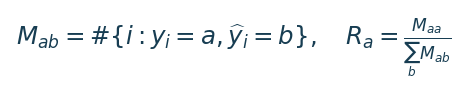

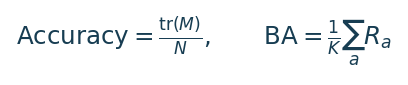

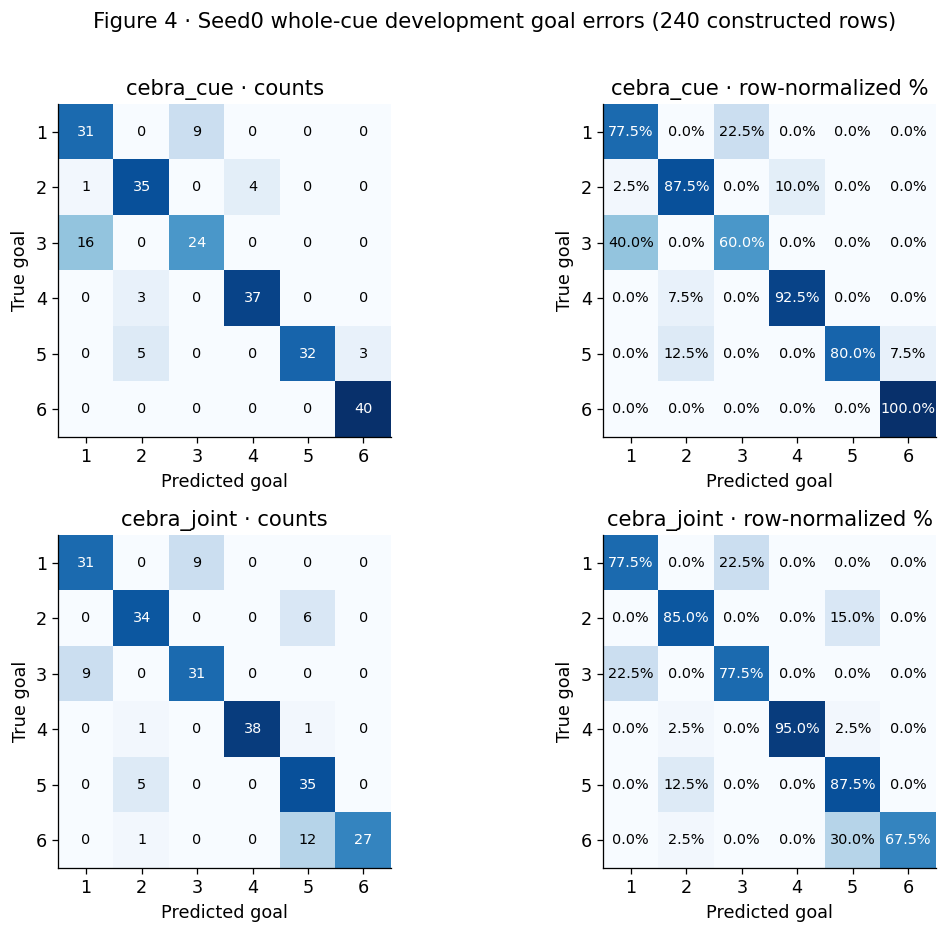

True goal,Correct / support,Recall
1,31 / 40,77.50%
2,35 / 40,87.50%
3,24 / 40,60.00%
4,37 / 40,92.50%
5,32 / 40,80.00%
6,40 / 40,100.00%


Worked BA = mean of the six displayed recalls = 82.9167%
Accuracy = 199 / 240 = 82.9167%


In [11]:
equation(r'M_{ab}=\\#\\{i:y_i=a,\\widehat{y}_i=b\\},\\quad R_a=\\frac{M_{aa}}{\\sum_b M_{ab}}'.replace('\\\\','\\'))
equation(r'\\mathrm{Accuracy}=\\frac{\\mathrm{tr}(M)}{N},\\qquad\\mathrm{BA}=\\frac{1}{K}\\sum_a R_a'.replace('\\\\','\\'))
fig, axes = plt.subplots(2,2,figsize=(10,8))
for i, rep in enumerate(('cebra_cue','cebra_joint')):
    matrix = confusions[0][rep,'goal6']
    recall = matrix / matrix.sum(axis=1, keepdims=True)
    np.testing.assert_array_equal(matrix.sum(axis=1), np.full(6,40))
    for j, values in enumerate((matrix,100*recall)):
        ax=axes[i,j]
        ax.imshow(values, cmap='Blues', vmin=0, vmax=40 if j==0 else 100)
        for a in range(6):
            for b in range(6):
                ax.text(b,a,f'{values[a,b]:.0f}' if j==0 else f'{values[a,b]:.1f}%',
                        ha='center',va='center',color='white' if values[a,b]>(20 if j==0 else 50) else 'black',fontsize=9)
        ax.set(xticks=range(6),yticks=range(6),xticklabels=range(1,7),yticklabels=range(1,7),
               xlabel='Predicted goal',ylabel='True goal',title=rep+(' · counts' if j==0 else ' · row-normalized %'))
fig.suptitle('Figure 4 · Seed0 whole-cue development goal errors (240 constructed rows)',y=1.01)
fig.tight_layout();show(fig)
m=confusions[0]['cebra_cue','goal6']
recalls=m.diagonal()/m.sum(axis=1)
table(['True goal','Correct / support','Recall'], [[i+1,f'{m[i,i]} / {m[i].sum()}',f'{100*recalls[i]:.2f}%'] for i in range(6)])
print(f'Worked BA = mean of the six displayed recalls = {100*recalls.mean():.4f}%')
print(f'Accuracy = {m.trace()} / {m.sum()} = {100*m.trace()/m.sum():.4f}%')


## 7. What the recovered results actually support

Figure 5 compares all methods on the same source assemblies within each seed. Every panel
uses concatenated 0–1 s cue input and the fitted readout appropriate to that method. Bars
are means; dots are the three computational seeds. There are **no biological confidence
intervals**. These are three assemblies/optimization repeats on one exposed source split,
not three independently held-out folds.


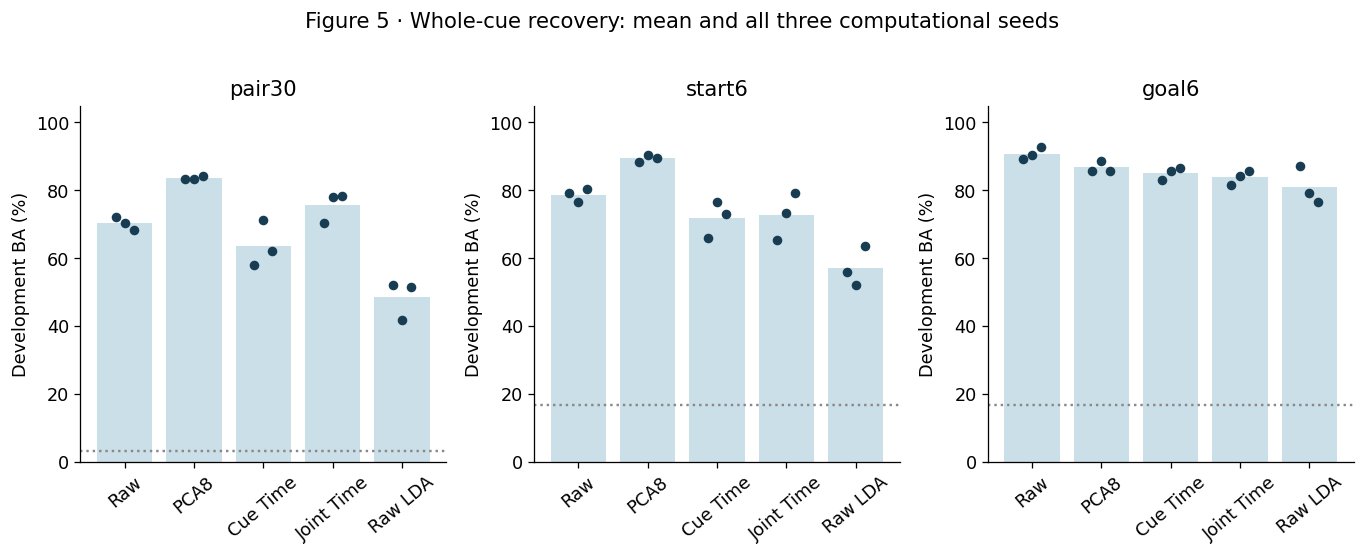

Method,Pair BA,Start BA,Goal BA
Raw,70.28%,78.75%,90.83%
PCA8,83.61%,89.44%,86.81%
Cue Time,63.75%,71.81%,85.14%
Joint Time,75.56%,72.64%,83.89%
Raw LDA,48.47%,57.22%,80.97%


Target,Joint − cue: seed0 / seed1 / seed2 (pp),Mean difference (pp)
pair30,+12.50 / +6.67 / +16.25,+11.81
start6,-0.42 / -3.33 / +6.25,+0.83
goal6,-1.25 / -1.67 / -0.83,-1.25


In [12]:
names = {'raw':'Raw', 'pca8':'PCA8', 'cebra_cue':'Cue Time', 'cebra_joint':'Joint Time', 'raw_svd_lda':'Raw LDA'}
def scores(rep,target,window='wholecue',split='development'):
    return np.array([next(r['balanced_accuracy'] for r in results if key(r)==(s,rep,window,target,split)) for s in range(3)])
fig,axes=plt.subplots(1,3,figsize=(12,4.7))
for ax,target in zip(axes,TARGETS,strict=True):
    for i,rep in enumerate(REPRESENTATIONS):
        values=100*scores(rep,target)
        ax.bar(i,values.mean(),color='#cbdfe8')
        ax.scatter(i+np.array([-0.13,0,0.13]),values,color='#183d52',s=25,zorder=3)
    ax.axhline(100/(30 if target=='pair30' else 6),color='#888',ls=':',label='Uniform reference')
    ax.set(xticks=range(5),xticklabels=[names[r] for r in REPRESENTATIONS],ylim=(0,105),
           ylabel='Development BA (%)',title=target)
    ax.tick_params(axis='x',rotation=40)
fig.suptitle('Figure 5 · Whole-cue recovery: mean and all three computational seeds',y=1.02)
fig.tight_layout();show(fig)
table(['Method','Pair BA','Start BA','Goal BA'],[[names[rep],*[f'{100*scores(rep,t).mean():.2f}%' for t in TARGETS]] for rep in REPRESENTATIONS])
table(['Target','Joint − cue: seed0 / seed1 / seed2 (pp)','Mean difference (pp)'],[
    [t,' / '.join(f'{v:+.2f}' for v in 100*(scores('cebra_joint',t)-scores('cebra_cue',t))),
     f"{100*(scores('cebra_joint',t)-scores('cebra_cue',t)).mean():+.2f}"] for t in TARGETS])


**Interpretation:** PCA has the highest mean pair/start BA in this comparison; raw features
lead goal BA. Joint CEBRA improves pair BA relative to cue-only, has a small mean start
gain and does not improve goal BA. This is not uniform CEBRA or joint-training superiority.
A paired difference is meaningful because the two arms use identical development
assemblies within a seed; it does not turn seeds into independent biological replicates.

The original whole-cue arm-gain control did **not** establish robust joint superiority.
This notebook defers shuffle figures and probability-loss metrics, but does not change
historical success criteria or reinterpret their failure as success. Those analyses remain
in the [original report](../docs/reports/cebra-endpoint-time-readout-20261006/README.md).

### Generalization gap and time-specific readouts

A small training–development gap can mean both scores are poor. Read the gap with absolute
performance, not as a method ranking. The horizontal axis below is time after cue onset,
**not training updates**. Each 100-ms bin has a separately fitted readout. This is not a
frozen-decoder train-time × test-time transfer matrix and does not identify a validated best bin.


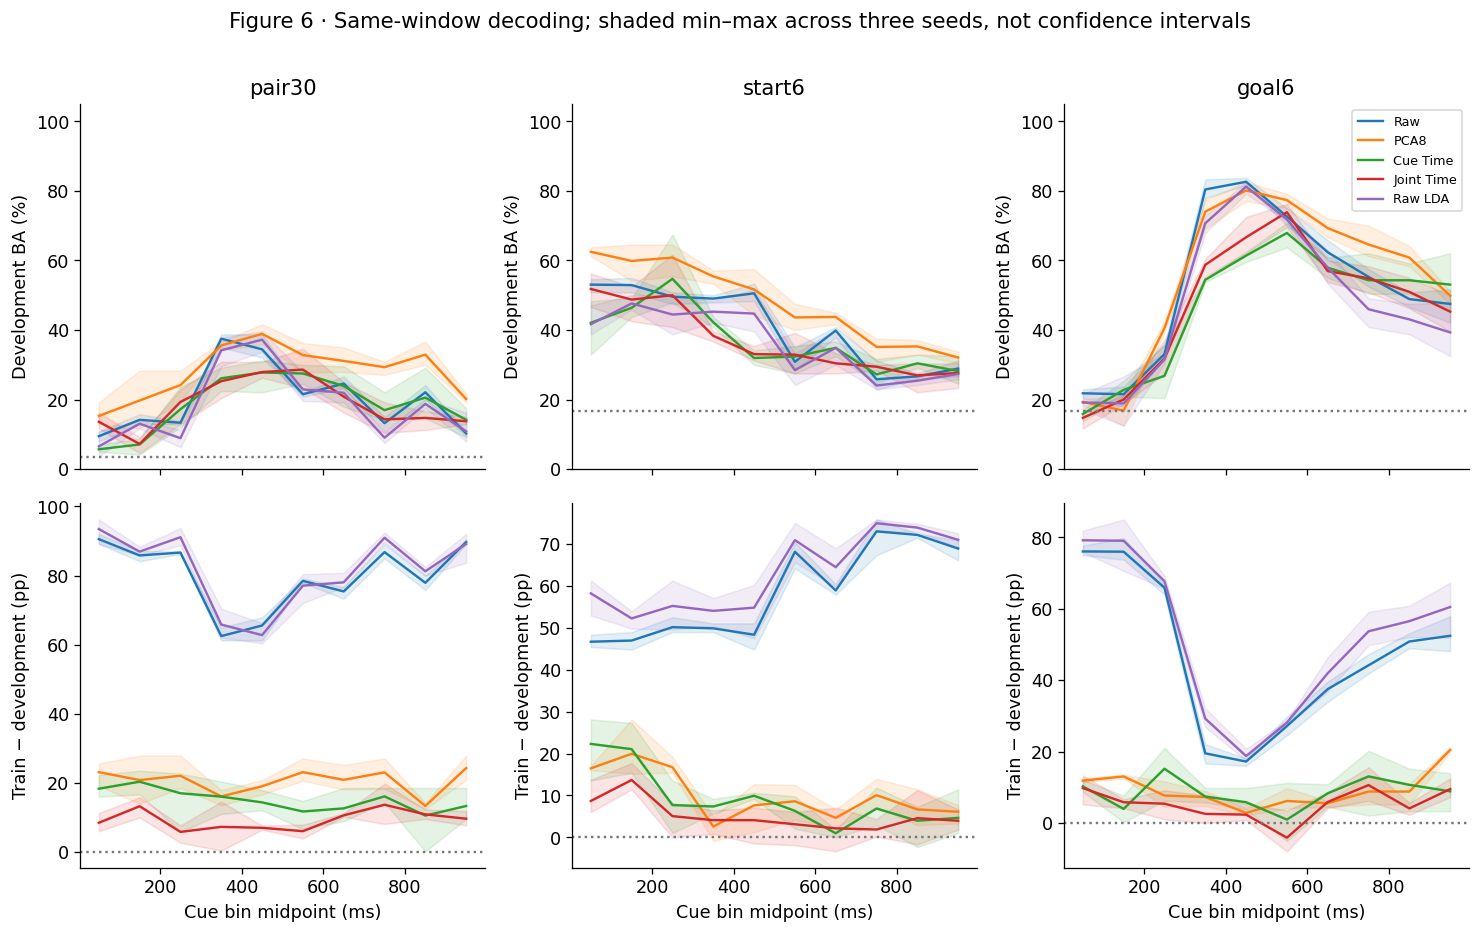

In [13]:
fig,axes=plt.subplots(2,3,figsize=(13,8),sharex=True)
colors=plt.rcParams['axes.prop_cycle'].by_key()['color']
centers=np.arange(50,1000,100)
for col,target in enumerate(TARGETS):
    for color,rep in zip(colors[:len(REPRESENTATIONS)],REPRESENTATIONS,strict=True):
        dev=np.array([scores(rep,target,f'bin{i:02d}') for i in range(10)])*100
        train=np.array([scores(rep,target,f'bin{i:02d}','train') for i in range(10)])*100
        gap=train-dev
        for row,values in enumerate((dev,gap)):
            axes[row,col].plot(centers,values.mean(axis=1),color=color,label=names[rep])
            axes[row,col].fill_between(centers,values.min(axis=1),values.max(axis=1),color=color,alpha=.12)
    axes[0,col].axhline(100/(30 if target=='pair30' else 6),color='#777',ls=':')
    axes[1,col].axhline(0,color='#777',ls=':')
    axes[0,col].set(title=target,ylabel='Development BA (%)',ylim=(0,105))
    axes[1,col].set(xlabel='Cue bin midpoint (ms)',ylabel='Train − development (pp)')
axes[0,2].legend(fontsize=8)
fig.suptitle('Figure 6 · Same-window decoding; shaded min–max across three seeds, not confidence intervals',y=1.01)
fig.tight_layout();show(fig)


## 8. Verification receipt and the boundary of the conclusion

The notebook is successful only if the final checks below pass. The replay is bounded to
observed inputs: **no raw recording access, no navigation access, no null-world replay and
no fits**. The package's full historical verifier is deliberately not called. The six
encoder replays and 495 readouts are inference through saved models, not new experimental fits.

Interpretation remains limited by known-label assembly, repeated development exposure,
place-selected units, provisional endpoint semantics and incompletely controlled visual,
behavioral/history and session covariates. Reproducible computation cannot establish
simultaneity or fix those measurement limits. Endpoint recovery does not test path information
beyond endpoints; the separate path cohort is not pooled here. H1 remains unresolved; H2 is removed.

**Not supplied:** original scaler-fit/source-array reconstruction, current-model training
trajectories, formal observability analysis, and a defined neural “within-bin variability”
panel. The seed ranges shown here are computational variation, not neural variability.
Missing diagnostics are stated rather than filled by new fitting.


In [14]:
assert len(feature_errors)==24  # 3 seeds × 2 splits × 4 representations
assert len(results)==990 and len(confusions)==3
assert all(len(confusions[s])==15 for s in range(3))
# Show that the active guard rejects a real fitting entry point without fitting anything.
from sklearn.preprocessing import StandardScaler
try:
    with no_fitting():
        StandardScaler().fit(np.zeros((2,2)))
except RuntimeError as error:
    assert 'forbids fitting' in str(error)
else:
    raise AssertionError('Fit guard did not reject the request')
source_hashes = [(p, hashlib.sha256((ROOT/p).read_bytes()).hexdigest()) for p in (
    'report/endpoint_replay.py','src/neuro/studies/endpoint_time_readout.py',
    'src/neuro/studies/full_trial_transfer.py','src/neuro/cebra_solver.py')]
table(['Verification item','Outcome'],[
    ['Manifest and every opened artifact','Authenticated against pinned hashes'],
    ['Saved source lineage','Three seeds checked; disjoint train/development sources'],
    ['Input-scaler fitting / raw reconstruction','Not rerun; historical evidence only'],
    ['Encoder inference','6 restored CEBRA encoders; original CUDA backend'],
    ['PCA transformation','3 saved PCA states; original float32 sklearn arithmetic'],
    ['Saved readouts / score rows','495 / 990; predictions, probabilities, accuracy and BA checked'],
    ['Maximum feature error',f"{max(r['max_abs_error'] for r in feature_errors):.3g}"],
    ['Maximum probability error',f'{max(probability_errors):.3g}'],
    ['Authenticated files opened',len(RUN.accessed)],
    ['New model fits','0; fit guard negative check passed'],
])
table(['Current implementation (not historical source identity)','SHA256'],source_hashes)
print('END-TO-END SAVED-INPUT REPLAY PASSED. Scientific scope remains exploratory and condition-level.')


Verification item,Outcome
Manifest and every opened artifact,Authenticated against pinned hashes
Saved source lineage,Three seeds checked; disjoint train/development sources
Input-scaler fitting / raw reconstruction,Not rerun; historical evidence only
Encoder inference,6 restored CEBRA encoders; original CUDA backend
PCA transformation,3 saved PCA states; original float32 sklearn arithmetic
Saved readouts / score rows,"495 / 990; predictions, probabilities, accuracy and BA checked"
Maximum feature error,0
Maximum probability error,0
Authenticated files opened,1024
New model fits,0; fit guard negative check passed


Current implementation (not historical source identity),SHA256
report/endpoint_replay.py,fc7a03ad46c7dddbd832cbe5df771293f3f780fc9b1a2aa4f8ad18d5151b86b4
src/neuro/studies/endpoint_time_readout.py,478a203962815df8d64a0ecce0a7cd9c068a77bef5b522851c9e71e92bce9a33
src/neuro/studies/full_trial_transfer.py,62988dc39d322b6f742629c92989481ef4dc652896c43cf8bbb0d204106d78c4
src/neuro/cebra_solver.py,8d193549d20c447204c19d03e89df14240038cfa7b9ff44636ad83dc5a4f1208


END-TO-END SAVED-INPUT REPLAY PASSED. Scientific scope remains exploratory and condition-level.


## Professor review guide

1. **Scientific object:** is condition-level endpoint information the correct interpretation
   of these constructed populations, and which laboratory metadata should qualify it further?
2. **Measurement/assembly:** does the source-support discussion make clear what is recorded,
   what is reused, and what is synthetic? The saved scaler fit is not rederived here.
3. **Comparisons:** are raw/PCA/LDA appropriate references? Joint training changes phase exposure
   and cue exposure; what narrower claim would be scientifically meaningful?
4. **Next use:** should a later notebook inspect temporal reuse or a verified simultaneous
   population? Neither experiment is authorized or launched by this notebook.

### Evidence and code
- [October endpoint protocol](../docs/reports/cebra-endpoint-time-readout-20261006/protocol.md),
  [accepted results](../docs/reports/cebra-endpoint-time-readout-20261006/README.md),
  [tracked seed/window metrics](../docs/reports/cebra-endpoint-time-readout-20261006/tables/observed_metrics_by_seed.csv),
  [historical provenance](../docs/reports/cebra-endpoint-time-readout-20261006/provenance.json).
- [Notebook replay adapter](endpoint_replay.py): authentication, restore/replay and aggregate-only return values;
  [package implementation](../src/neuro/studies/endpoint_time_readout.py): shared target/window/encoder logic.
- [Analysis contract](../docs/analysis-contract.md), [manuscript](README.md),
  [separate future-research agenda](../docs/cebra-observability-agenda-20261011.md).
- CEBRA: Schneider, Lee & Mathis (2023),
  [*Learnable latent embeddings for joint behavioural and neural analysis*](https://doi.org/10.1038/s41586-023-06031-6).
  This supports the methodological framework, not biological validation of our dataset.

**Reproduction instructions and limits:** see [the report README](README.md#saved-artifact-notebook-execution-and-boundaries).
The public notebook contains code, equations, diagrams and aggregate outputs. It deliberately
contains no neural input arrays, individual source identifiers, checkpoints or per-row predictions.
